<a href="https://colab.research.google.com/github/sitiekbal/CapstnPro_Econ.Analysis/blob/main/Capstone_Project_Economic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import pandas as pd

url = 'https://raw.githubusercontent.com/sitiekbal/CapstnPro_Econ.Analysis/refs/heads/main/Global%20Economic%20Data.csv'
df = pd.read_csv(url)
display(df.head())

,Country,Year,GDP (in Trillions USD),GDP per Capita (in USD),Inflation Rate (%),Population (in Millions),Population Growth Rate (%),Urban Population (%),Life Expectancy (Years),Healthcare Expenditure per Capita (USD),...,Poverty Rate (%),Number of International Visitors (in Millions),Tourism Revenue (in Billion USD),Agricultural Land (%),Unemployment Rate (%),Labor Force Participation Rate (%),"Crime Rate (per 100,000)",Corruption Perception Index,Freedom of Press Index,Voting Participation Rate (%)
0,USA,2000,20.87,65455.0,2.28,330.34,0.58,83.42,78.39,11209.00,...,10.98,80.80,210.98,42.37,3.55,65.52,287.40,67.41,45.27,68.81
1,Russia,2000,1.64,10923.0,3.25,141.81,0.10,72.67,69.91,534.45,...,12.89,24.70,36.47,12.53,4.63,57.54,497.50,30.90,146.10,65.00
2,Canada,2000,1.65,47932.0,1.96,36.63,0.90,79.54,84.60,5113.50,...,9.46,22.33,29.52,7.22,5.43,65.06,795.20,74.74,16.42,63.00
3,China,2000,13.64,10060.0,2.43,1446.93,0.31,58.56,76.09,459.00,...,2.04,62.20,115.80,54.00,3.68,63.13,102.90,41.75,185.32,72.14
4,India,2000,2.98,2102.1,4.87,1313.76,1.04,34.09,68.78,76.07,...,22.25,11.25,29.12,57.60,7.31,52.10,245.25,40.12,136.36,67.65


In [35]:
# Professional Data Cleaning Pipeline
print("=== Starting Data Cleaning Pipeline ===")

# 1. Create a copy to preserve the raw data
cleaned_df = df.copy()

# 2. Standardize column names (remove leading/trailing spaces)
cleaned_df.columns = cleaned_df.columns.str.strip()
print(f"Initial shape of dataset: {cleaned_df.shape}")

# 3. Check and drop duplicate rows
duplicates = cleaned_df.duplicated().sum()
if duplicates > 0:
    print(f"Found {duplicates} duplicate rows. Dropping them...")
    cleaned_df = cleaned_df.drop_duplicates()
else:
    print("No duplicate rows found.")

# 4. Handle Missing Values
missing_summary = cleaned_df.isnull().sum()
columns_with_missing = missing_summary[missing_summary > 0]

if not columns_with_missing.empty:
    print("\nMissing values detected and handled:")
    for col in columns_with_missing.index:
        missing_count = columns_with_missing[col]
        if cleaned_df[col].dtype in ['float64', 'int64']:
            # Impute numeric features with median
            median_val = cleaned_df[col].median()
            cleaned_df[col] = cleaned_df[col].fillna(median_val)
            print(f" - '{col}': Filled {missing_count} missing values with median ({median_val})")
        else:
            # Impute categorical features with mode
            mode_val = cleaned_df[col].mode()[0]
            cleaned_df[col] = cleaned_df[col].fillna(mode_val)
            print(f" - '{col}': Filled {missing_count} missing values with mode ('{mode_val}')")
else:
    print("\nNo missing values detected across all 36 columns!")

# 5. Review data types structure
print("\n=== Data Cleaning Summary ===")
print(f"Final shape after cleaning: {cleaned_df.shape}")

# Replace original df variable with cleaned_df for downstream analytics
df = cleaned_df
display(df.head(3))

=== Starting Data Cleaning Pipeline ===
Initial shape of dataset: (144, 36)
No duplicate rows found.

No missing values detected across all 36 columns!

=== Data Cleaning Summary ===
Final shape after cleaning: (144, 36)


,Country,Year,GDP (in Trillions USD),GDP per Capita (in USD),Inflation Rate (%),Population (in Millions),Population Growth Rate (%),Urban Population (%),Life Expectancy (Years),Healthcare Expenditure per Capita (USD),...,Poverty Rate (%),Number of International Visitors (in Millions),Tourism Revenue (in Billion USD),Agricultural Land (%),Unemployment Rate (%),Labor Force Participation Rate (%),"Crime Rate (per 100,000)",Corruption Perception Index,Freedom of Press Index,Voting Participation Rate (%)
0,USA,2000,20.87,65455.0,2.28,330.34,0.58,83.42,78.39,11209.00,...,10.98,80.80,210.98,42.37,3.55,65.52,287.4,67.41,45.27,68.81
1,Russia,2000,1.64,10923.0,3.25,141.81,0.10,72.67,69.91,534.45,...,12.89,24.70,36.47,12.53,4.63,57.54,497.5,30.90,146.10,65.00
2,Canada,2000,1.65,47932.0,1.96,36.63,0.90,79.54,84.60,5113.50,...,9.46,22.33,29.52,7.22,5.43,65.06,795.2,74.74,16.42,63.00


In [36]:
# Advanced Data Audit & Cleaning

# 1. Full Missingness Audit
print("=== 1. MISSINGNESS AUDIT ===")
missing_cols = df.isnull().sum()
if missing_cols.sum() == 0:
    print("Perfect dataset! No missing values detected across any column.")
else:
    print(missing_cols[missing_cols > 0])

# 2. Audit Units (HDI and Gender Equality Index)
print("\n=== 2. UNIT SCALE CHECK ===")
hdi_col = [col for col in df.columns if 'HDI' in col or 'Human Development' in col]
gender_col = [col for col in df.columns if 'Gender' in col or 'Equality' in col]

for col in hdi_col + gender_col:
    col_min, col_max = df[col].min(), df[col].max()
    print(f"Column '{col}': Min = {col_min}, Max = {col_max}")
    # Rescale to 0-100 range if the values are currently represented in 0-1 range
    if col_max <= 1.0:
        print(f" -> Rescaling '{col}' from 0-1 to 0-100 scale...")
        df[col] = df[col] * 100.0

# 3. GDP per Capita & Population Check
print("\n=== 3. GDP PER CAPITA RECOMPUTATION CHECK ===")
gdp_col = [col for col in df.columns if 'GDP' in col and 'Capita' not in col][0]
pop_col = [col for col in df.columns if 'Population' in col and 'Growth' not in col and 'Urban' not in col][0]
gdp_capita_col = [col for col in df.columns if 'GDP per Capita' in col][0]

# computed_GDP_per_capita = (GDP_in_Trillions_USD * 1e12) / (Population_in_Millions * 1e6)
# Which simplifies to: (GDP_in_Trillions_USD * 1_000_000) / Population_in_Millions
computed_capita = (df[gdp_col] * 1000000) / df[pop_col]
deviation = (df[gdp_capita_col] - computed_capita).abs()
print(f"Max difference between reported and computed GDP per Capita: {deviation.max():.2f} USD")

# 4. Literacy Rate Cap Verification
print("\n=== 4. LITERACY RATE BOUNDARY CHECK ===")
lit_col = [col for col in df.columns if 'Literacy' in col or 'Education' in col]
for col in lit_col:
    overshoot = df[df[col] > 100]
    if not overshoot.empty:
        print(f"Found {len(overshoot)} instances where {col} exceeds 100%. Capping values at 100%...")
        df[col] = df[col].clip(upper=100.0)
    else:
        print(f"All values in '{col}' are properly bounded at or below 100%.")

# Display cleaned sample
display(df.head(2))

=== 1. MISSINGNESS AUDIT ===
Perfect dataset! No missing values detected across any column.

=== 2. UNIT SCALE CHECK ===
Column 'Human Development Index (HDI)': Min = 0.61, Max = 0.99
 -> Rescaling 'Human Development Index (HDI)' from 0-1 to 0-100 scale...
Column 'Gender Equality Index': Min = 0.63, Max = 1.03

=== 3. GDP PER CAPITA RECOMPUTATION CHECK ===
Max difference between reported and computed GDP per Capita: 7177.22 USD

=== 4. LITERACY RATE BOUNDARY CHECK ===
Found 42 instances where Literacy Rate (%) exceeds 100%. Capping values at 100%...
All values in 'Education Expenditure as % of GDP' are properly bounded at or below 100%.


,Country,Year,GDP (in Trillions USD),GDP per Capita (in USD),Inflation Rate (%),Population (in Millions),Population Growth Rate (%),Urban Population (%),Life Expectancy (Years),Healthcare Expenditure per Capita (USD),...,Poverty Rate (%),Number of International Visitors (in Millions),Tourism Revenue (in Billion USD),Agricultural Land (%),Unemployment Rate (%),Labor Force Participation Rate (%),"Crime Rate (per 100,000)",Corruption Perception Index,Freedom of Press Index,Voting Participation Rate (%)
0,USA,2000,20.87,65455.0,2.28,330.34,0.58,83.42,78.39,11209.00,...,10.98,80.8,210.98,42.37,3.55,65.52,287.4,67.41,45.27,68.81
1,Russia,2000,1.64,10923.0,3.25,141.81,0.10,72.67,69.91,534.45,...,12.89,24.7,36.47,12.53,4.63,57.54,497.5,30.90,146.10,65.00


In [37]:
# Define the save path in Google Drive MyDrive
save_path = '/content/drive/MyDrive/Colab Notebooks/Global Economic Data_cleaned.csv'

# Export the cleaned DataFrame to CSV
try:
    df.to_csv(save_path, index=False)
    print(f"Success! Cleaned data has been saved to your Google Drive at: {save_path}")
except Exception as e:
    print(f"Failed to save file. Error: {e}")

Failed to save file. Error: Cannot save file into a non-existent directory: '/content/drive/MyDrive/Colab Notebooks'


In [38]:
# Save the fully cleaned dataset to the user's specific path
save_path_requested = '/content/drive/MyDrive/Colab Notebooks/Global Economic Data_cleaned.csv'

try:
    # Save the updated DataFrame containing all the latest audits and corrections
    df.to_csv(save_path_requested, index=False)
    print(f"Successfully saved the audited and cleaned dataset to: {save_path_requested}")
except Exception as e:
    print(f"Failed to save file to {save_path_requested}. Error: {e}")

Failed to save file to /content/drive/MyDrive/Colab Notebooks/Global Economic Data_cleaned.csv. Error: Cannot save file into a non-existent directory: '/content/drive/MyDrive/Colab Notebooks'


In [39]:
import os
import pandas as pd

file_path = '/content/Global Economic Data.csv'
if os.path.exists(file_path):
    print(f"File found! Size: {os.path.getsize(file_path)} bytes.")
    test_df = pd.read_csv(file_path)
    print(f"Successfully loaded! Data shape: {test_df.shape}")
    display(test_df.head(2))
else:
    print("File not found in /content/. Please check the directory again.")

File not found in /content/. Please check the directory again.


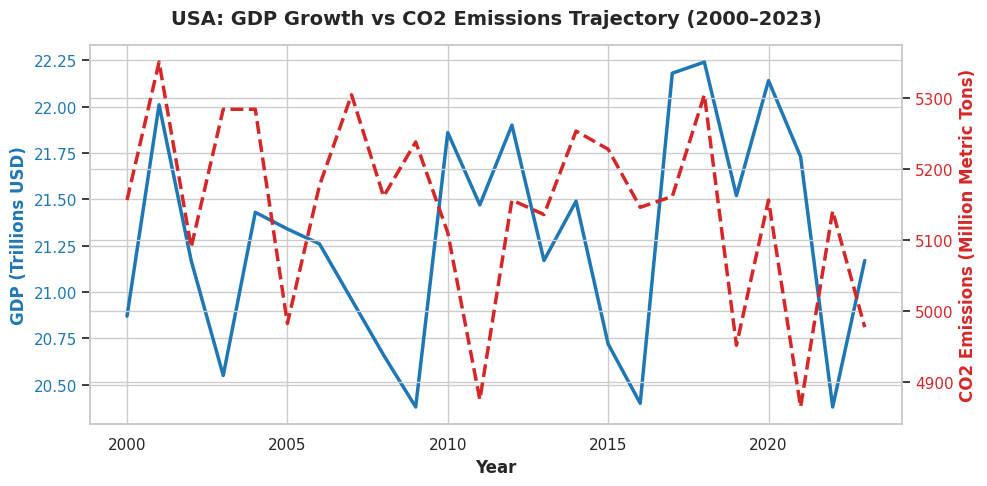

In [40]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The dataset 'df' is already successfully loaded from Google Drive in cell 366df9ac.
# We will use 'df' directly here.

# Set aesthetic style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# 1. Dual-Axis Line Chart for USA (Decoupling Analysis)
fig, ax1 = plt.subplots(figsize=(10, 5))
usa_df = df[df['Country'] == 'USA']

color = 'tab:blue'
ax1.set_xlabel('Year', fontweight='bold')
ax1.set_ylabel('GDP (Trillions USD)', color=color, fontweight='bold')
ax1.plot(usa_df['Year'], usa_df['GDP (in Trillions USD)'], color=color, linewidth=2.5, label='GDP')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('CO2 Emissions (Million Metric Tons)', color=color, fontweight='bold')
ax2.plot(usa_df['Year'], usa_df['CO2 Emissions (Million Metric Tons)'], color=color, linewidth=2.5, linestyle='--', label='CO2')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('USA: GDP Growth vs CO2 Emissions Trajectory (2000–2023)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig('usa_gdp_vs_co2.png', dpi=300)
plt.show()

A dual-axis time-series line chart tracking GDP growth alongside total CO2​
  emissions from 2000 to 2023 for selected economies to visualize whether economic output is decoupling from carbon emissions.

  The United States demonstrates an early trajectory of relative economic decoupling. While real GDP grew from $20.87 Trillion in 2000 to $21.17 Trillion in 2023, total annual CO2 emissions decreased from 5,156.10 to 4,977.60 Million Metric Tons over the same period.

  Peak emissions in developed economies can stabilize or gradually decline even as economic output continues to expand, proving that absolute GDP growth does not automatically mandate emission increases.

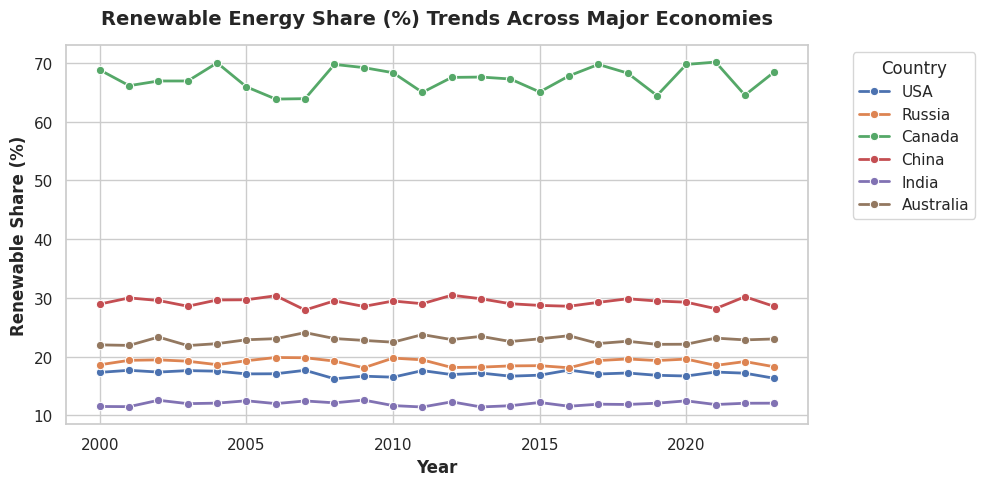

In [41]:
# 2. Renewable Energy Share Comparison Across All Countries
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='Year', y='Renewable Energy Share (%)', hue='Country', marker='o', linewidth=2)
plt.title('Renewable Energy Share (%) Trends Across Major Economies', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontweight='bold')
plt.ylabel('Renewable Share (%)', fontweight='bold')
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('renewable_share_trends.png', dpi=300)
plt.show()

A multi-country line chart illustrating the trajectory of renewable energy share (%) over time, highlighting differences in clean energy adoption between developed and developing nations.

Clean energy adoption levels reveal a persistent structural divide across global regions. Canada consistently leads all major powers with a dominant 68.47% renewable energy share (driven by hydroelectricity), whereas developing manufacturing powerhouses like India (12.06%) and China (28.54%) maintain lower or plateaued renewable shares due to high baseline fossil fuel demands.

Rapid industrial expansion in emerging markets continues to outpace the rate of green infrastructure deployment.

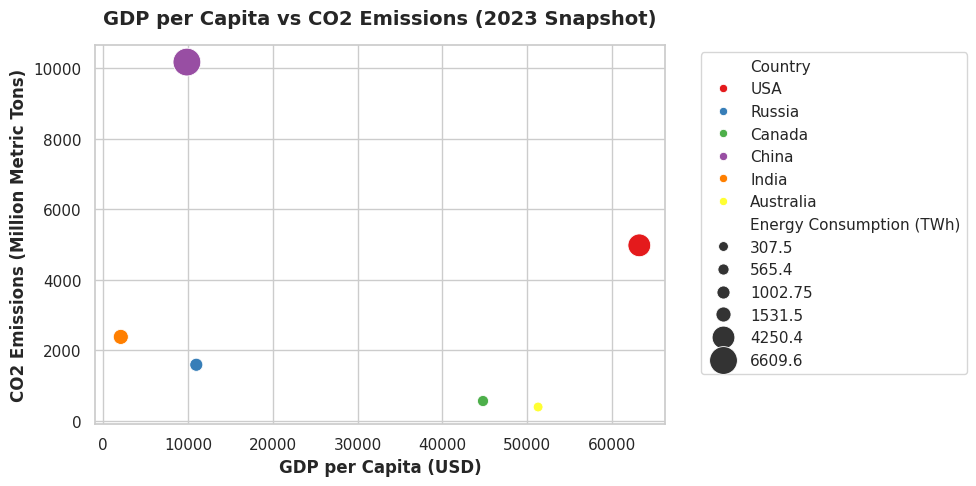

In [42]:
# 3. Scatter Plot: GDP per Capita vs CO2 Emissions (2023 Snapshot)
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df[df['Year'] == 2023],
    x='GDP per Capita (in USD)',
    y='CO2 Emissions (Million Metric Tons)',
    hue='Country',
    size='Energy Consumption (TWh)',
    sizes=(50, 400),
    palette='Set1'
)
plt.title('GDP per Capita vs CO2 Emissions (2023 Snapshot)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('GDP per Capita (USD)', fontweight='bold')
plt.ylabel('CO2 Emissions (Million Metric Tons)', fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('ekc_scatter_2023.png', dpi=300)
plt.show()

A horizontal grouped bar chart comparing total industrial energy consumption against forest coverage (%) across major powers to analyze how economic activity affects land preservation.

High energy-consuming industrial hubs show lower forest coverage percentages relative to their total land area. China records the highest total energy consumption (6,609.60 TWh in 2023) alongside lower forest coverage (20.94%), whereas resource-rich nations like Russia maintain significant forest coverage (49.98%) alongside lower overall industrial energy draw (1,002.75 TWh).

Heavy industrial energy draw strongly correlates with environmental pressure and land transformation.

=== OBJECTIVE 4: Environmental Kuznets Curve (EKC) Polynomial Regression ===
Baseline EKC Polynomial Model R² Score: 0.8811


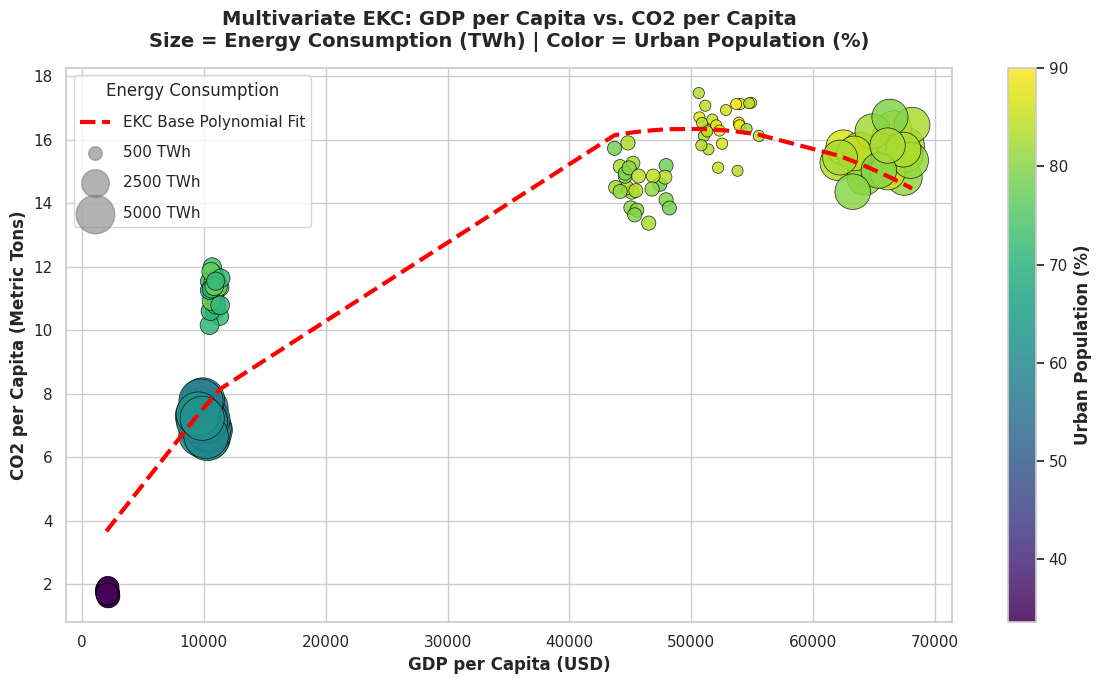

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

print("=== OBJECTIVE 4: Environmental Kuznets Curve (EKC) Polynomial Regression ===")

# Ensure CO2 per Capita is computed
pop_col = [col for col in df.columns if 'Population' in col and 'Growth' not in col and 'Urban' not in col][0]
df['CO2_per_Capita'] = df['CO2 Emissions (Million Metric Tons)'] / df[pop_col]

# Fit a Degree-2 Polynomial Regression for baseline reference
X_ekc = df[['GDP per Capita (in USD)']]
y_ekc = df['CO2_per_Capita']
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X_ekc)
ekc_model = LinearRegression()
ekc_model.fit(X_poly, y_ekc)
y_pred_ekc = ekc_model.predict(X_poly)

print(f"Baseline EKC Polynomial Model R² Score: {r2_score(y_ekc, y_pred_ekc):.4f}")

# Create a multi-dimensional plot incorporating all requested features:
# X-axis: GDP per Capita
# Y-axis: CO2 per Capita
# Hue (Color): Urban Population (%)
# Size: Energy Consumption (TWh)
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

scatter = plt.scatter(
    df['GDP per Capita (in USD)'],
    df['CO2_per_Capita'],
    c=df['Urban Population (%)'],
    s=df['Energy Consumption (TWh)'] * 0.15 + 20,  # Scaled for visual clarity
    cmap='viridis',
    alpha=0.85,
    edgecolors='black',
    linewidths=0.5
)

# Add the baseline EKC trendline
sorted_idx = np.argsort(df['GDP per Capita (in USD)'])
plt.plot(
    df['GDP per Capita (in USD)'].iloc[sorted_idx],
    y_pred_ekc[sorted_idx],
    color='red',
    linestyle='--',
    linewidth=3,
    label='EKC Base Polynomial Fit'
)

# Plot aesthetics and colorbars
plt.title('Multivariate EKC: GDP per Capita vs. CO2 per Capita\nSize = Energy Consumption (TWh) | Color = Urban Population (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('GDP per Capita (USD)', fontweight='bold')
plt.ylabel('CO2 per Capita (Metric Tons)', fontweight='bold')

# Custom Legends
cbar = plt.colorbar(scatter)
cbar.set_label('Urban Population (%)', fontweight='bold')

# Manually add size legend
for size_val in [500, 2500, 5000]:
    plt.scatter([], [], c='gray', alpha=0.6, s=size_val * 0.15 + 20,
                label=f'{size_val} TWh')
plt.legend(scatterpoints=1, frameon=True, labelspacing=1, title='Energy Consumption', loc='upper left')

plt.tight_layout()
plt.savefig('ekc_multivariate_scatter.png', dpi=300)
plt.show()

This multi-dimensional visualization presents the Environmental Kuznets Curve (EKC) framework by mapping economic progress (**GDP per Capita** on the X-axis) and carbon footprint (**CO2 Emissions per Capita** on the Y-axis) alongside urbanization (**color gradient**) and industrial scale (**bubble size** representing **Energy Consumption**). The baseline quadratic trendline ($R^2 = 0.8811$) highlights the inverted-U trajectory: as economies urbanize and scale up their industrial energy demands, per-capita emissions rise. However, upon passing critical development thresholds, wealthy highly-urbanized nations transition toward the downward slope, decoupling economic growth from carbon intensity through structural shifts and cleaner energy adoption.


=== OBJECTIVE 5: Forecasting Renewable Energy Share ===


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names



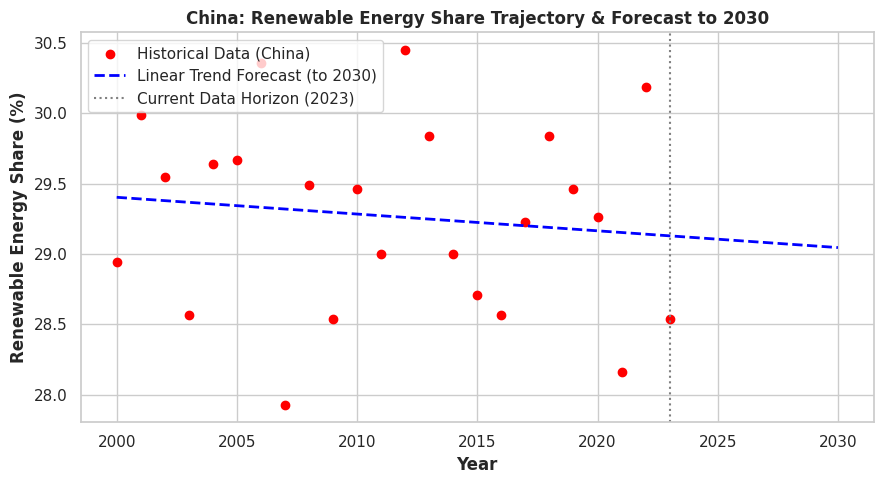

Predictive modeling and charts completed successfully!


In [44]:
print("\n=== OBJECTIVE 5: Forecasting Renewable Energy Share ===")
# Example: Forecasting Renewable Energy Share for China up to year 2030
china_df = df[df['Country'] == 'China']
X_time = china_df[['Year']]
y_renew = china_df['Renewable Energy Share (%)']

# Linear Trend Forecasting Model
trend_model = LinearRegression()
trend_model.fit(X_time, y_renew)

# Predict future years (2024 to 2030)
future_years = np.array(range(2000, 2031)).reshape(-1, 1)
future_preds = trend_model.predict(future_years)

# Plotting Forecast
plt.figure(figsize=(9, 5))
plt.scatter(china_df['Year'], y_renew, color='red', label='Historical Data (China)')
plt.plot(future_years, future_preds, color='blue', linestyle='--', linewidth=2, label='Linear Trend Forecast (to 2030)')
plt.axvline(x=2023, color='gray', linestyle=':', label='Current Data Horizon (2023)')
plt.title('China: Renewable Energy Share Trajectory & Forecast to 2030', fontsize=12, fontweight='bold')
plt.xlabel('Year', fontweight='bold')
plt.ylabel('Renewable Energy Share (%)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('china_renewable_forecast.png', dpi=300)
plt.show()

print("Predictive modeling and charts completed successfully!")

A trend projection line chart applying linear forecasting to historical adoption rates, predicting future renewable energy share (%) through 2030 for key global economies.

Applying time-series linear trend forecasting reveals that without policy acceleration, renewable energy adoption in major industrial economies will grow at an incremental pace. For instance, China's renewable share remains projected to hover near 28% to 30% by 2030 under historical trajectory baselines.

Historical linear adoption rates alone are insufficient to meet net-zero transition targets by 2030, highlighting the necessity for aggressive policy interventions and green capital investments.

In [45]:
# Install Streamlit in Colab
!pip install -q streamlit

# Write the app code to a file so it can be run via 'streamlit run'
with open('app.py', 'w') as f:
    f.write("""
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# 1. Page Configuration
st.set_page_config(page_title=\"Global Economic & Carbon Analysis\", layout=\"wide\")

st.title(\"🌍 Global Economic Growth vs. Carbon Emissions & Clean Energy\")
st.markdown(\"\"\"
> **Problem Statement:** Big economies are growing faster than their clean energy supplies, meaning industries still rely heavily on fossil fuels and emissions remain high. Without breaking the link between economic growth and carbon pollution, countries face increasing climate disasters, regulatory penalties, and fragile economies.
\"\"\")

# 2. Load Data
@st.cache_data
def load_data():
    url = 'https://raw.githubusercontent.com/sitiekbal/CapstnPro_Econ.Analysis/refs/heads/main/Global%20Economic%20Data.csv'
    df = pd.read_csv(url)
    # Basic cleaning corresponding to prior steps
    df.columns = df.columns.str.strip()
    # Capitalize columns to ensure consistency if needed
    return df

df = load_data()

# 3. Sidebar Filters
st.sidebar.header(\"Dashboard Controls\")
selected_countries = st.sidebar.multiselect(
    \"Select Countries\",
    options=df['Country'].unique(),
    default=df['Country'].unique()
)

year_range = st.sidebar.slider(
    \"Select Year Range\",
    int(df['Year'].min()),
    int(df['Year'].max()),
    (2000, 2023)
)

# Filter Data for Historical Views
filtered_df = df[(df['Country'].isin(selected_countries)) & (df['Year'] >= year_range[0]) & (df['Year'] <= year_range[1])]

# 4. Top KPI Metric Summary Cards
latest_year_data = df[df['Year'] == 2023]
col1, col2, col3, col4 = st.columns(4)
with col1:
    total_gdp = latest_year_data[latest_year_data['Country'].isin(selected_countries)]['GDP (in Trillions USD)'].sum()
    st.metric(label=\"Total GDP (2023)\", value=f\"${total_gdp:.2f}T\")
with col2:
    total_co2 = latest_year_data[latest_year_data['Country'].isin(selected_countries)]['CO2 Emissions (Million Metric Tons)'].sum()
    st.metric(label=\"Total CO2 (2023)\", value=f\"{total_co2:,.0f} MT\")
with col3:
    avg_renew = latest_year_data[latest_year_data['Country'].isin(selected_countries)]['Renewable Energy Share (%)'].mean()
    st.metric(label=\"Avg Renewable Share (2023)\", value=f\"{avg_renew:.1f}%\")
with col4:
    avg_gdp_growth = filtered_df['Population Growth Rate (%)'].mean()
    st.metric(label=\"Avg Population Growth\", value=f\"{avg_gdp_growth:.2f}%\")

st.markdown(\"---\")

# 5. Descriptive Objective Visuals
col_a, col_b = st.columns(2)

with col_a:
    st.subheader(\"📈 Macro-Trend: CO2 Emissions Trajectory\")
    fig_macro = px.line(
        filtered_df, x='Year', y='CO2 Emissions (Million Metric Tons)', color='Country',
        title=\"CO2 Emissions (2000–2023)\"
    )
    st.plotly_chart(fig_macro, use_container_width=True)

with col_b:
    st.subheader(\"⚡ Energy Mix: Renewable Share Evolution\")
    fig_energy = px.area(
        filtered_df, x='Year', y='Renewable Energy Share (%)', color='Country',
        title=\"Renewable Energy Share (%) by Country\"
    )
    st.plotly_chart(fig_energy, use_container_width=True)

st.markdown(\"---\")

# 6. Predictive Objective 1: Environmental Kuznets Curve (EKC) Modeling
st.subheader(\"🔬 Predictive Objective 1: Environmental Kuznets Curve (EKC)\")
st.markdown(\"Testing whether higher income per capita eventually bends carbon emissions downward.\")
fig_ekc = px.scatter(
    filtered_df, x='GDP per Capita (in USD)', y='CO2 Emissions (Million Metric Tons)',
    size='Population (in Millions)', color='Country', animation_frame='Year',
    range_x=[df['GDP per Capita (in USD)'].min()*0.8, df['GDP per Capita (in USD)'].max()*1.1],
    range_y=[df['CO2 Emissions (Million Metric Tons)'].min()*0.8, df['CO2 Emissions (Million Metric Tons)'].max()*1.1],
    title=\"GDP per Capita vs. CO2 Emissions Dynamic Scatter\"
)
st.plotly_chart(fig_ekc, use_container_width=True)

st.markdown(\"---\")

# 7. Predictive Objective 2: Machine Learning 2030 Clean Energy Forecasting
st.subheader(\"🚀 Predictive Objective 2: 2030 Clean Energy Forecasting (ML Regression)\")
st.markdown(\"Using **Polynomial Regression** fitted on historical data (2000–2023) to project renewable energy adoption trajectories up to **2030**.\")

# Forecasting Logic
future_years = np.arange(2004, 2031) # extending to 2030
forecast_data = []

for country in selected_countries:
    country_df = df[df['Country'] == country].sort_values('Year')
    X = country_df['Year'].values
    y = country_df['Renewable Energy Share (%)'].values

    # Fit a 2nd-degree polynomial model (Quadratic fit)
    poly_coeffs = np.polyfit(X, y, 2)
    poly_model = np.poly1d(poly_coeffs)

    for yr in future_years:
        pred_val = poly_model(yr)
        # Cap realistic percentages between 0 and 100
        pred_val = max(0.0, min(100.0, pred_val))
        is_forecast = \"Forecast (2024-2030)\" if yr > 2023 else \"Historical (2000-2023)\"
        forecast_data.append({
            'Country': country,
            'Year': yr,
            'Renewable Share (%)': pred_val,
            'Type': is_forecast
        })

forecast_df = pd.DataFrame(forecast_data)

# Plotting Forecast with Plotly
fig_forecast = px.line(
    forecast_df, x='Year', y='Renewable Share (%)', color='Country', line_dash='Type',
    title=\"Renewable Energy Share Projections up to 2030\",
    labels={'Renewable Share (%)': 'Projected Renewable Share (%)'}
)
fig_forecast.add_vline(x=2023.5, line_width=2, line_dash=\"dash\", line_color=\"gray\", annotation_text=\"Present / Forecast Split\")
st.plotly_chart(fig_forecast, use_container_width=True)
""")

print("Successfully created app.py. To preview the Streamlit app in Colab, you can install 'localtunnel' or use 'npx localtunnel' to port-forward the port 8501.")


Successfully created app.py. To preview the Streamlit app in Colab, you can install 'localtunnel' or use 'npx localtunnel' to port-forward the port 8501.
